# Hierarchical Two-Stage IndoBERTweet for Cyberbullying Detection

Code accompanying the paper **"A Hierarchical Two Stage BERT Model for Cyberbullying Detection"**,
*IJNMT* Vol. 13 No. 1 (2026), pp. 57–64. DOI: [10.31937/ijnmt.v13i1.4730](https://doi.org/10.31937/ijnmt.v13i1.4730)

**Pipeline**

1. **Stage 1:** binary classification, `not_bullying` vs `bullying`.
2. **Stage 2:** tweets labelled as bullying are classified into `harrasment`, `denigration` or `exclusion`.

Both stages fine-tune [`indolem/indobertweet-base-uncased`](https://huggingface.co/indolem/indobertweet-base-uncased).
The saved outputs below come from the run reported in the paper.

## 1. Setup

In [ ]:
!pip install -q transformers datasets torch scikit-learn accelerate

In [ ]:
import re

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
)

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

## 2. Data loading and preprocessing

In [ ]:
# Adjust this path if you run on Colab (e.g. after uploading the file)
DATA_PATH = "../data/dataset.xlsx"
df = pd.read_excel(DATA_PATH)
df.head()

,full_text,label
0,yaelah seller pepek. awas ya kalo lu nyalahin ...,harrasment
1,Ahya tololl mikir dikit napa anjengg waktu urg...,harrasment
2,Wkwk masih ngakak tapi nih anak gampang banget...,harrasment
3,Tolong aku mau misuh2 anjing goblok tolol bang...,harrasment
4,jahat banget anjing motivasi dia begini apaan ...,harrasment


In [ ]:
print(f'shape: {df.shape}')

shape: (300, 2)


In [ ]:
def clean_text(text):
    text = str(text).lower()
    # hapus URL
    text = re.sub(r'http\S+|www.\S+', '', text)
    # hapus mention
    text = re.sub(r'@\w+', '', text)
    # hapus hashtag
    text = re.sub(r'#[\w-]+', '', text)
    # hapus emoji/simbol
    text = re.sub(r'[^a-zA-Z0-9 ]', ' ', text)
    # normalisasi huruf berulang
    text = re.sub(r'(.)\1{2,}', r'\1', text)
    # hapus spasi berlebih
    text = re.sub(r'\s+', ' ', text).strip()
    return text

In [ ]:
df['clean_text'] = df['full_text'].apply(clean_text)
df.head()

,full_text,label,clean_text
0,yaelah seller pepek. awas ya kalo lu nyalahin ...,harrasment,yaelah seller pepek awas ya kalo lu nyalahin g...
1,Ahya tololl mikir dikit napa anjengg waktu urg...,harrasment,ahya tololl mikir dikit napa anjengg waktu urg...
2,Wkwk masih ngakak tapi nih anak gampang banget...,harrasment,wkwk masih ngakak tapi nih anak gampang banget...
3,Tolong aku mau misuh2 anjing goblok tolol bang...,harrasment,tolong aku mau misuh2 anjing goblok tolol bang...
4,jahat banget anjing motivasi dia begini apaan ...,harrasment,jahat banget anjing motivasi dia begini apaan ...


## 3. Stage 1: bullying vs not bullying

All non-`not_bullying` labels are merged into `bullying`. Split: 70% train / 15% validation / 15% test, stratified.

In [ ]:
df["label_stage1"] = df["label"].apply(
    lambda x: "bullying" if x != "not_bullying" else "not_bullying"
)

In [ ]:
label2id_stage1 = {"not_bullying": 0, "bullying": 1}
id2label_stage1 = {0: "not_bullying", 1: "bullying"}

df["label_stage1"] = df["label_stage1"].map(label2id_stage1)

In [ ]:
from sklearn.model_selection import train_test_split

# 1) Train (70%) + Temp (30%)
X_train, X_temp, y_train, y_temp = train_test_split(
    df["clean_text"],
    df["label_stage1"],   # 0 = not_bullying, 1 = bullying
    test_size=0.3,
    stratify=df["label_stage1"],
    random_state=42
)

# 2) Validation (15%) + Test (15%)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.5,
    stratify=y_temp,
    random_state=42
)

### Tokenization and datasets

In [ ]:
from transformers import AutoTokenizer

model_name = "indolem/indobertweet-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)

def tokenize(batch):
    return tokenizer(
        batch["text"],
        padding="max_length",
        truncation=True,
        max_length=128
    )

In [ ]:
from datasets import Dataset

train_ds = Dataset.from_dict({
    "text": X_train.tolist(),
    "label": y_train.tolist()
})

val_ds = Dataset.from_dict({
    "text": X_val.tolist(),
    "label": y_val.tolist()
})

test_ds = Dataset.from_dict({
    "text": X_test.tolist(),
    "label": y_test.tolist()
})

In [ ]:
train_ds = train_ds.map(tokenize, batched=True)
val_ds   = val_ds.map(tokenize, batched=True)
test_ds  = test_ds.map(tokenize, batched=True)

train_ds.set_format("torch", columns=["input_ids", "attention_mask", "label"])
val_ds.set_format("torch", columns=["input_ids", "attention_mask", "label"])
test_ds.set_format("torch", columns=["input_ids", "attention_mask", "label"])

### Training

In [ ]:
from transformers import AutoModelForSequenceClassification

id2label_stage1 = {0: "not_bullying", 1: "bullying"}
label2id_stage1 = {"not_bullying": 0, "bullying": 1}

model_stage1 = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2,
    id2label=id2label_stage1,
    label2id=label2id_stage1
)

In [ ]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="./stage1",
    eval_strategy="epoch",   # ⬅️ evaluasi tiap epoch
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=4,
    weight_decay=0.01,
    logging_steps=10,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    report_to="none"
)

In [ ]:
from transformers import Trainer

trainer_stage1 = Trainer(
    model=model_stage1,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,   # ⬅️ VALIDATION SET
    processing_class=tokenizer
)

In [ ]:
trainer_stage1.train()

Epoch,Training Loss,Validation Loss
1,0.573400,0.342957
2,0.312700,0.214691
3,0.095500,0.188729
4,0.086400,0.179221


TrainOutput(global_step=56, training_loss=0.22681591446910584, metrics={'train_runtime': 1367.2784, 'train_samples_per_second': 0.614, 'train_steps_per_second': 0.041, 'total_flos': 55253321625600.0, 'train_loss': 0.22681591446910584, 'epoch': 4.0})

### Training curves

In [ ]:
# Ambil log training
logs = trainer_stage1.state.log_history

# Ubah ke DataFrame
df_logs = pd.DataFrame(logs)

# Lihat isinya (opsional)
df_logs

,loss,grad_norm,learning_rate,epoch,step,eval_loss,eval_runtime,eval_samples_per_second,eval_steps_per_second,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
0,0.5734,4.151386,0.000017,0.714286,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,1.000000,14,0.342957,18.1578,2.478,0.165,NaN,NaN,NaN,NaN,NaN
2,0.3127,3.370330,0.000013,1.428571,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,2.000000,28,0.214691,18.3650,2.450,0.163,NaN,NaN,NaN,NaN,NaN
4,0.1711,2.378700,0.000010,2.142857,30,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,0.0955,2.105628,0.000006,2.857143,40,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,3.000000,42,0.188729,17.6845,2.545,0.170,NaN,NaN,NaN,NaN,NaN
7,0.0864,2.626422,0.000003,3.571429,50,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NaN,NaN,NaN,4.000000,56,0.179221,17.7988,2.528,0.169,NaN,NaN,NaN,NaN,NaN
9,NaN,NaN,NaN,4.000000,56,NaN,NaN,NaN,NaN,1367.2784,0.614,0.041,5.525332e+13,0.226816


In [ ]:
train_loss = df_logs[df_logs["loss"].notna()][["epoch", "loss"]]
val_loss = df_logs[df_logs["eval_loss"].notna()][["epoch", "eval_loss"]]

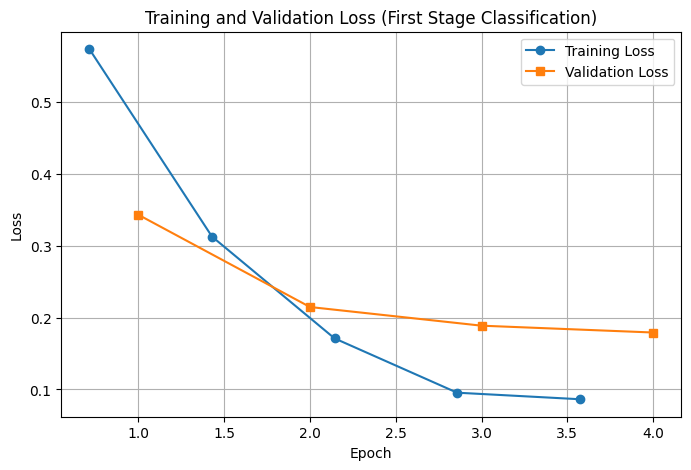

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(train_loss["epoch"], train_loss["loss"], marker='o', label="Training Loss")
plt.plot(val_loss["epoch"], val_loss["eval_loss"], marker='s', label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss (First Stage Classification)")
plt.legend()
plt.grid(True)

plt.show()

### Evaluation on the test set

In [ ]:
import numpy as np
from sklearn.metrics import classification_report

preds = trainer_stage1.predict(test_ds)

y_pred = np.argmax(preds.predictions, axis=1)
y_true = preds.label_ids

print(
    classification_report(
        y_true,
        y_pred,
        target_names=["not_bullying", "bullying"]
    )
)

              precision    recall  f1-score   support

not_bullying       1.00      1.00      1.00        22
    bullying       1.00      1.00      1.00        23

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



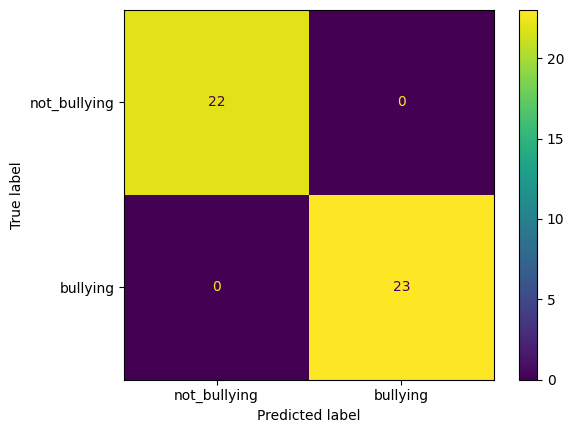

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["not_bullying", "bullying"]
)

disp.plot()
plt.show()

## 4. Stage 2: bullying type (harassment / denigration / exclusion)

Only bullying samples are used. Split: 70% train / 15% validation / 15% test, stratified by type.

In [ ]:
import random, torch, numpy as np
from transformers import set_seed

SEED = 42
set_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [ ]:
df_stage2 = df[df["label"] != "not_bullying"]

In [ ]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df_stage2,
    test_size=0.3,
    stratify=df_stage2["label"],
    random_state=42
)

valid_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    stratify=temp_df["label"],
    random_state=42
)

In [ ]:
from datasets import ClassLabel

class_label = ClassLabel(
    names=["harrasment", "denigration", "exclusion"]
)

In [ ]:
from datasets import Dataset

train_ds = Dataset.from_dict({
    "text": train_df["clean_text"].tolist(),
    "label": train_df["label"].tolist()
}).cast_column("label", class_label)

valid_ds = Dataset.from_dict({
    "text": valid_df["clean_text"].tolist(),
    "label": valid_df["label"].tolist()
}).cast_column("label", class_label)

test_ds = Dataset.from_dict({
    "text": test_df["clean_text"].tolist(),
    "label": test_df["label"].tolist()
}).cast_column("label", class_label)

In [ ]:
from transformers import AutoTokenizer

model_name = "indolem/indobertweet-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)

def tokenize(batch):
    return tokenizer(
        batch["text"],
        padding="max_length",
        truncation=True,
        max_length=128
    )

train_ds = train_ds.map(tokenize, batched=True)
valid_ds = valid_ds.map(tokenize, batched=True)
test_ds  = test_ds.map(tokenize, batched=True)

In [ ]:
train_ds.set_format("torch", columns=["input_ids", "attention_mask", "label"])
valid_ds.set_format("torch", columns=["input_ids", "attention_mask", "label"])
test_ds.set_format("torch",  columns=["input_ids", "attention_mask", "label"])

### Training

In [ ]:
from transformers import AutoModelForSequenceClassification

id2label_stage2 = {
    0: "harrasment",
    1: "denigration",
    2: "exclusion"
}

label2id_stage2 = {v: k for k, v in id2label_stage2.items()}

model_stage2 = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=3,
    id2label=id2label_stage2,
    label2id=label2id_stage2
)

In [ ]:
from transformers import TrainingArguments

training_args_stage2 = TrainingArguments(
    output_dir="./stage2",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=4,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    logging_steps=10,
    report_to="none"
)

In [ ]:
from transformers import Trainer

trainer_stage2 = Trainer(
    model=model_stage2,
    args=training_args_stage2,
    train_dataset=train_ds,
    eval_dataset=valid_ds,   # 🔑 VALIDATION SET
    processing_class=tokenizer
)

In [ ]:
trainer_stage2.train()

Epoch,Training Loss,Validation Loss
1,No log,0.876590
2,0.992800,0.713431


### Evaluation on the test set

In [ ]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

preds = trainer_stage2.predict(test_ds)

y_pred = np.argmax(preds.predictions, axis=1)
y_true = preds.label_ids

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_label.names
    )
)

              precision    recall  f1-score   support

  harrasment       0.88      1.00      0.93         7
 denigration       0.89      0.89      0.89         9
   exclusion       1.00      0.88      0.93         8

    accuracy                           0.92        24
   macro avg       0.92      0.92      0.92        24
weighted avg       0.92      0.92      0.92        24



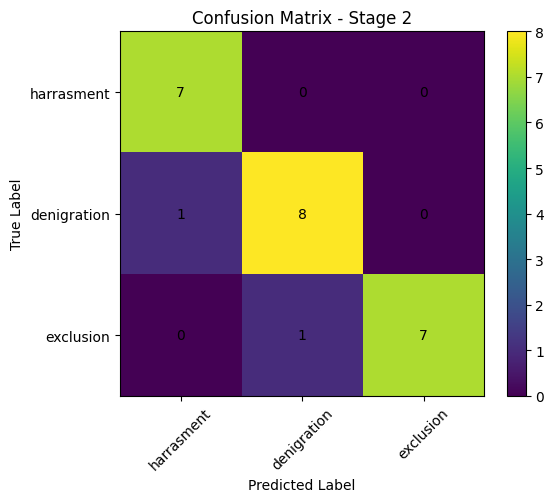

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix

# hitung confusion matrix
# Pass the full set of expected integer labels to confusion_matrix
cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(class_label.names)))

# label kelas (string names for plotting)
labels = class_label.names

# plot
plt.figure(figsize=(6, 5))
plt.imshow(cm)
plt.colorbar()

plt.xticks(np.arange(len(labels)), labels, rotation=45)
plt.yticks(np.arange(len(labels)), labels)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - Stage 2")

# isi angka di tiap sel
for i in range(len(labels)):
    for j in range(len(labels)):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()

## 5. Inference with the full two-stage pipeline

A text goes to Stage 2 only when Stage 1 predicts `bullying`.

In [ ]:
import torch
import numpy as np
from transformers import AutoTokenizer

# ===== Load tokenizer =====
tokenizer = AutoTokenizer.from_pretrained(
    "indolem/indobertweet-base-uncased"
)

# ===== Label mapping =====
id2label_stage1 = {0: "not_bullying", 1: "bullying"}
id2label_stage2 = {
    0: "harassment",
    1: "denigration",
    2: "exclusion"
}

# ===== Prediction function =====
def predict_texts(texts, model_stage1, model_stage2, max_len=128):
    model_stage1.eval()
    model_stage2.eval()

    encodings = tokenizer(
        texts,
        padding=True,
        truncation=True,
        max_length=max_len,
        return_tensors="pt"
    )

    results = []

    with torch.no_grad():
        # ----- Stage 1 -----
        outputs_stage1 = model_stage1(**encodings)
        preds_stage1 = torch.argmax(outputs_stage1.logits, dim=1)

        for i, pred1 in enumerate(preds_stage1):
            if pred1.item() == 1:  # bullying
                single_input = {
                    k: v[i].unsqueeze(0) for k, v in encodings.items()
                }

                # ----- Stage 2 -----
                outputs_stage2 = model_stage2(**single_input)
                pred2 = torch.argmax(outputs_stage2.logits, dim=1)

                results.append({
                    "text": texts[i],
                    "stage1": id2label_stage1[pred1.item()],
                    "stage2": id2label_stage2[pred2.item()]
                })
            else:
                results.append({
                    "text": texts[i],
                    "stage1": id2label_stage1[pred1.item()],
                    "stage2": None
                })

    return results

In [ ]:
texts = [
    "goblok bgtt gini aja gapaham",
    "Hmmm menarik sih idenya",
    "fadhil gausah diajak deh ganggu bgtt wkwkkw",
    "jokowi tukang kayu pembohong rakyat"
]

predictions = predict_texts(texts, model_stage1, model_stage2)

for p in predictions:
    print(p)

{'text': 'goblok bgtt gini aja gapaham', 'stage1': 'bullying', 'stage2': 'harassment'}
{'text': 'Hmmm menarik sih idenya', 'stage1': 'not_bullying', 'stage2': None}
{'text': 'fadhil gausah diajak deh ganggu bgtt wkwkkw', 'stage1': 'bullying', 'stage2': 'exclusion'}
{'text': 'jokowi tukang kayu pembohong rakyat', 'stage1': 'bullying', 'stage2': 'denigration'}
